In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive
Mounted at /content/drive


In [2]:
!pip install pykan -q
import warnings, os, math, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from scipy.stats import norm
from kan import KAN

warnings.filterwarnings('ignore')
pd.set_option('display.width', 180)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("device:", device)

device: cuda
device: cuda


In [7]:
DATA_DIR = '/content/drive/MyDrive/data_files'
BOND_FILE = f"{DATA_DIR}/bond_yield.csv"

ASSET_FILES = {
    'NIFTY50': {
        'options': f"{DATA_DIR}/NIFTY_raw.csv",
        'spot':    f"{DATA_DIR}/nifty_spot.csv",
        'symbol':  'NIFTY',
    },
    'BANKNIFTY': {
        'options': f"{DATA_DIR}/BANKNIFTY_raw.csv",
        'spot':    f"{DATA_DIR}/banknifty_spot.csv",
        'symbol':  'BANKNIFTY',
    },
}

USE_PAPER_DATE_SPLIT = True      # False -> old behaviour: 70:30 chronological split of whatever is loaded
DATA_START = '2015-01-01'        # option rows before this are dropped (2014 spot is still used for lookback)
TRAIN_END  = '2017-09-30'
DATA_END   = '2018-12-31'        # set both DATA_START / DATA_END to None to keep everything loaded

# ---- COVID-period test (Sec. 7): same pre-trained models, Jan 2019 - Apr 2020 data ----
RUN_COVID    = True
COVID_START  = '2019-01-01'
COVID_END    = '2020-04-30'
CRASH_START  = '2020-03-01'      # only used to split the COVID results into pre-crash / crash
COVID_APPROACHES = ['Approach III']          # paper uses III; add 'Approach I', 'Approach II' if wanted
COVID_FILES = {                  # same layouts as ASSET_FILES; point 'options' at the 2019-2020 file(s)
    'NIFTY50': {
        'options': f"{DATA_DIR}/NIFTY_covid_raw.csv",
        'spot':    f"{DATA_DIR}/nifty_spot.csv",
        'symbol':  'NIFTY',
    },
    'BANKNIFTY': {'options': f"{DATA_DIR}/BANKNIFTY_covid_raw.csv",
                  'spot':    f"{DATA_DIR}/banknifty_spot.csv", 'symbol': 'BANKNIFTY'},
}


# ---- filtering / binning (paper values) --------------------------------
LOOKBACK   = 20
DTE_MIN, DTE_MAX = 3, 45
ATM_BAND   = 0.04
W_BIN      = 0.1        # bin width on the 100*C/K scale
BIN_COVER  = 98.0       # percentile of pooled data below the overflow bin
TRAIN_FRAC = 0.70
OPTION_TYPE = 'CE'
SEED = 42
YEAR_FILTER = None

# Approach II: the original notebook kept only mu_C and commented out mu_O/mu_H/mu_L.
# False reproduces that choice (14 features); True gives the paper's 17.
USE_ALL_OHLC_MEANS = True

# ---- KAN hyperparameters ----------------------------------------------
KAN_HIDDEN   = [32, 16]
KAN_GRID, KAN_K = 5, 3
KAN_LR, KAN_LAMB = 1e-3, 1e-4
CHUNK_STEPS  = 5        # steps between validation checks
MAX_STEPS    = 8000
PATIENCE     = 5
BATCH        = 4096     # clamped below the val-set size automatically; -1 = full batch
PRED_CHUNK   = 2048     # forward-pass chunk size, keeps KAN activation memory bounded

QUICK_MODE = False      # True -> MAX_STEPS=200, for a fast end-to-end dry run
if QUICK_MODE:
    MAX_STEPS = 200

print("Assets:", list(ASSET_FILES))

Assets: ['NIFTY50', 'BANKNIFTY']


In [8]:
def load_bond_yields(path):
    bonds = pd.read_csv(path)
    bonds.columns = ['date', 'risk_free_rate', 'rf_open', 'rf_high', 'rf_low', 'change_pct']
    bonds['date'] = pd.to_datetime(bonds['date'], errors='coerce')
    for c in ['risk_free_rate', 'rf_open', 'rf_high', 'rf_low']:
        bonds[c] = pd.to_numeric(bonds[c].astype(str).str.replace(',', ''), errors='coerce')
    bonds.loc[bonds['risk_free_rate'] > 50, 'risk_free_rate'] = np.nan   # sentinel prints
    bonds = bonds.dropna(subset=['date']).sort_values('date')
    bonds['risk_free_rate'] = bonds['risk_free_rate'].ffill().bfill()
    full = pd.date_range(bonds['date'].min(), bonds['date'].max(), freq='D')
    return (bonds.set_index('date')[['risk_free_rate']]
                 .reindex(full).rename_axis('date').ffill().reset_index())


def load_spot(path):
    spot = pd.read_csv(path)
    if 'TIMESTAMP' in spot.columns:
        spot = spot.drop(columns=['TIMESTAMP'])
    spot.columns = ['date', 'spot_close', 'spot_high', 'spot_low', 'spot_open', 'spot_volume']
    spot['date'] = pd.to_datetime(spot['date'], errors='coerce')
    for c in ['spot_close', 'spot_high', 'spot_low', 'spot_open', 'spot_volume']:
        spot[c] = pd.to_numeric(spot[c].astype(str).str.replace(',', ''), errors='coerce')
    return spot.dropna(subset=['date']).sort_values('date').reset_index(drop=True)


import glob

def _parse_dates(col):
    """Handles '27-DEC-2018', '27-Dec-2018', '2018-12-27' and day-first fallbacks in one column."""
    s = col.astype(str).str.strip()
    out = pd.to_datetime(s, format='%d-%b-%Y', errors='coerce')
    m = out.isna()
    if m.any():
        out[m] = pd.to_datetime(s[m], format='%Y-%m-%d', errors='coerce')
    m = out.isna()
    if m.any():
        out[m] = pd.to_datetime(s[m], errors='coerce', dayfirst=True)
    return out


def _expand(paths):
    if isinstance(paths, (list, tuple)):
        files = [f for p in paths for f in (sorted(glob.glob(p)) or [p])]
    else:
        files = sorted(glob.glob(paths)) or [paths]
    return files


# bhavcopy column -> internal name
BHAV_COLS = {'INSTRUMENT': 'instrument', 'SYMBOL': 'symbol', 'EXPIRY_DT': 'expiry',
             'STRIKE_PR': 'strike', 'OPTION_TYP': 'option_type', 'OPEN': 'open', 'HIGH': 'high',
             'LOW': 'low', 'CLOSE': 'close', 'SETTLE_PR': 'settle_price', 'CONTRACTS': 'contracts',
             'VAL_INLAKH': 'turnover_lakhs', 'OPEN_INT': 'open_interest',
             'CHG_IN_OI': 'change_in_oi', 'TIMESTAMP': 'date'}
OLD_COLS = ['symbol', 'date', 'expiry', 'option_type', 'strike',
            'open', 'high', 'low', 'close', 'ltp', 'settle_price',
            'contracts', 'turnover_lakhs', 'premium_turnover_lakhs',
            'open_interest', 'change_in_oi', 'underlying']
NUM_COLS = ['strike', 'open', 'high', 'low', 'close', 'ltp', 'settle_price', 'contracts',
            'turnover_lakhs', 'premium_turnover_lakhs', 'open_interest', 'change_in_oi', 'underlying']


def _read_one_option_file(path, symbol=None):
    raw = pd.read_csv(path, low_memory=False)
    raw = raw.drop(columns=[c for c in raw.columns if str(c).startswith('Unnamed')], errors='ignore')
    raw.columns = [str(c).strip() for c in raw.columns]

    if {'TIMESTAMP', 'EXPIRY_DT', 'STRIKE_PR'} <= set(c.upper() for c in raw.columns):      # (a) bhavcopy
        raw.columns = [c.upper() for c in raw.columns]
        opt = raw.rename(columns=BHAV_COLS)[[v for v in BHAV_COLS.values() if v in raw.rename(columns=BHAV_COLS)]]
        if 'instrument' in opt:                       # keep index options only (drops OPTSTK / OPTFUT rows)
            opt = opt[opt['instrument'].astype(str).str.strip().str.upper() == 'OPTIDX']
        if symbol is not None:                        # one file can hold NIFTY, BANKNIFTY, FINNIFTY ...
            opt = opt[opt['symbol'].astype(str).str.strip().str.upper() == symbol.upper()]
        for c in ('ltp', 'premium_turnover_lakhs', 'underlying'):
            opt[c] = np.nan                           # not in this layout; underlying comes from the spot file
    else:                                             # (b) legacy 17-column layout, positional
        opt = raw.copy()
        opt.columns = OLD_COLS
    return opt


def load_options(paths, symbol=None):
    opt = pd.concat([_read_one_option_file(p, symbol) for p in _expand(paths)], ignore_index=True)
    opt['date'] = _parse_dates(opt['date'])
    opt['expiry'] = _parse_dates(opt['expiry'])
    for c in NUM_COLS:
        opt[c] = pd.to_numeric(opt[c].astype(str).str.replace(',', ''), errors='coerce')
    opt['option_type'] = opt['option_type'].astype(str).str.strip().str.upper()
    opt = opt.dropna(subset=['date', 'expiry', 'strike'])
    return opt.drop_duplicates(subset=['date', 'expiry', 'option_type', 'strike'], keep='last')


def build_lookback_frame(spot, lookback=LOOKBACK):
    lb = spot[['date', 'spot_open', 'spot_high', 'spot_low', 'spot_close']].copy()
    for lag in range(1, lookback + 1):
        lb[f'und_open_lag{lag}']  = lb['spot_open'].shift(lag)
        lb[f'und_high_lag{lag}']  = lb['spot_high'].shift(lag)
        lb[f'und_low_lag{lag}']   = lb['spot_low'].shift(lag)
        lb[f'und_close_lag{lag}'] = lb['spot_close'].shift(lag)
    return (lb.drop(columns=['spot_open', 'spot_high', 'spot_low', 'spot_close'])
              .dropna().reset_index(drop=True))


def build_asset_dataset(name, files, bonds, verbose=True, date_min=None, date_max=None):
    counts = {}
    opt = load_options(files['options'], symbol=files.get('symbol'))
    counts['raw'] = len(opt)
    spot = load_spot(files['spot'])

    opt = opt.merge(spot[['date', 'spot_close']], on='date', how='left')
    opt['underlying'] = opt['spot_close']
    opt = opt.drop(columns=['spot_close']).dropna(subset=['underlying'])

    if OPTION_TYPE is not None:
        opt = opt[opt['option_type'] == OPTION_TYPE]
    opt = opt[(opt['contracts'].fillna(0) > 0) & (opt['turnover_lakhs'].fillna(0) > 0)]

    opt['days_to_expiry'] = (opt['expiry'] - opt['date']).dt.days
    opt = opt[(opt['days_to_expiry'] >= DTE_MIN) & (opt['days_to_expiry'] <= DTE_MAX)]

    opt['moneyness_gap'] = (1 - opt['underlying'] / opt['strike']).abs()
    opt = opt[opt['moneyness_gap'] <= ATM_BAND]

    opt = opt.sort_values(['expiry', 'option_type', 'strike', 'date'])
    opt['prev_day_close'] = opt.groupby(['expiry', 'option_type', 'strike'])['close'].shift(1)
    opt = opt.dropna(subset=['prev_day_close'])

    opt = opt.merge(build_lookback_frame(spot), on='date', how='inner')
    opt = opt.merge(spot, on='date', how='left')
    opt = opt.merge(bonds, on='date', how='left')
    opt['risk_free_rate'] = opt['risk_free_rate'].ffill().bfill()
    opt['time_to_maturity_yrs'] = opt['days_to_expiry'] / 365.0
    opt['asset'] = name

    if YEAR_FILTER is not None:
        opt = opt[opt['date'].dt.year == YEAR_FILTER]
    # date window is applied LAST so earlier rows still feed prev_day_close and the spot lookback
    if date_min is not None:
        opt = opt[opt['date'] >= pd.Timestamp(date_min)]
    if date_max is not None:
        opt = opt[opt['date'] <= pd.Timestamp(date_max)]

    opt = opt.sort_values('date').reset_index(drop=True)
    counts['filtered'] = len(opt)
    if verbose:
        print(f"[{name}] raw={counts['raw']:,}  filtered={counts['filtered']:,}  "
              f"({opt['date'].min().date()} to {opt['date'].max().date()})")
    return opt, counts

In [10]:
bonds = load_bond_yields(BOND_FILE)

DATA, COUNTS = {}, {}
for name, files in ASSET_FILES.items():
    DATA[name], COUNTS[name] = build_asset_dataset(name, files, bonds, date_min=DATA_START, date_max=DATA_END)

ASSETS = list(DATA)
MULTI_ASSET = len(ASSETS) >= 2
print("\nassets loaded:", ASSETS, "| multi-asset regimes enabled:", MULTI_ASSET)

[NIFTY50] raw=1,087,289  filtered=16,333  (2015-01-02 to 2018-12-24)
[BANKNIFTY] raw=360,162  filtered=24,898  (2015-01-01 to 2018-12-24)

assets loaded: ['NIFTY50', 'BANKNIFTY'] | multi-asset regimes enabled: True


In [11]:
pooled_ratio = pd.concat([100 * d['close'] / d['strike'] for d in DATA.values()], ignore_index=True)
pooled_raw = np.ceil(pooled_ratio / W_BIN).astype(int).clip(lower=1)

counts_sorted = pooled_raw.value_counts().sort_index()
cum_pct = counts_sorted.cumsum() / counts_sorted.sum() * 100
CUTOFF_BIN = int(cum_pct[cum_pct <= BIN_COVER].index.max())
NUM_CLASSES = 50

print(f"Pooled data: bins 1-{CUTOFF_BIN} cover ~{BIN_COVER}%  ->  NUM_CLASSES = {NUM_CLASSES}")

for name, d in DATA.items():
    d['output_ratio'] = 100 * d['close'] / d['strike']
    d['bin_label_raw'] = np.ceil(d['output_ratio'] / W_BIN).astype(int).clip(lower=1)
    d['bin_label'] = np.where(d['bin_label_raw'] > CUTOFF_BIN, NUM_CLASSES, d['bin_label_raw'])
    share = 100 * (d['bin_label'] == NUM_CLASSES).mean()
    print(f"[{name}] bins {d['bin_label'].min()}-{d['bin_label'].max()}, "
          f"overflow bin holds {share:.2f}% of rows")

Pooled data: bins 1-44 cover ~98.0%  ->  NUM_CLASSES = 50
[NIFTY50] bins 1-50, overflow bin holds 2.41% of rows
[BANKNIFTY] bins 1-50, overflow bin holds 2.55% of rows


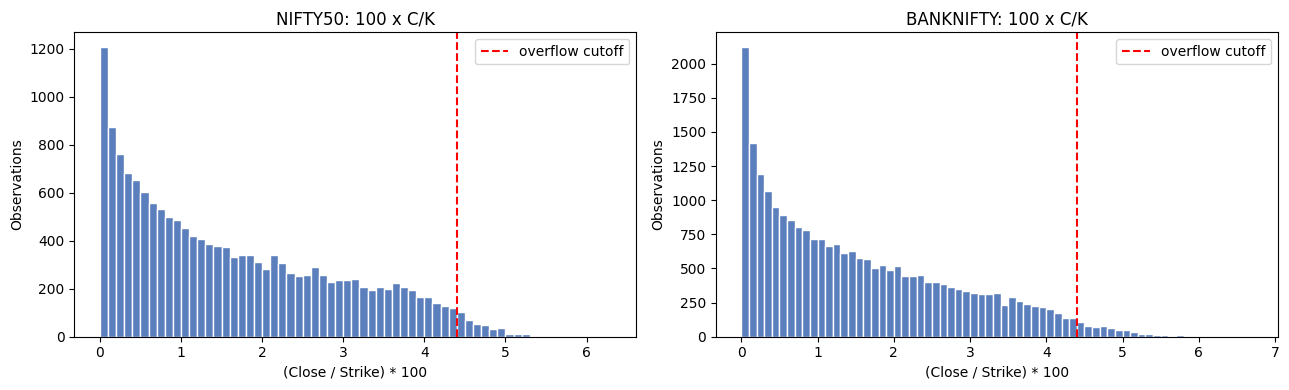

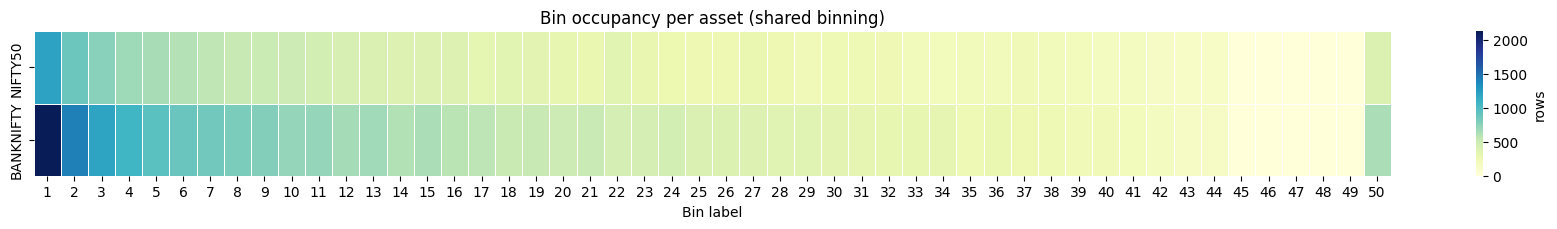

In [12]:
fig, axes = plt.subplots(1, len(DATA), figsize=(6.5*len(DATA), 4), squeeze=False)
for ax, (name, d) in zip(axes[0], DATA.items()):
    ax.hist(d['output_ratio'], bins=np.arange(0, d['output_ratio'].max()+W_BIN, W_BIN),
            color='#5b7fbd', edgecolor='white')
    ax.axvline(CUTOFF_BIN * W_BIN, color='red', ls='--', label='overflow cutoff')
    ax.set_xlabel('(Close / Strike) * 100'); ax.set_ylabel('Observations')
    ax.set_title(f'{name}: 100 x C/K'); ax.legend()
plt.tight_layout(); plt.show()

# per-bin occupancy on the pooled scale
occ = pd.DataFrame({name: d['bin_label'].value_counts().reindex(range(1, NUM_CLASSES+1), fill_value=0)
                    for name, d in DATA.items()})
plt.figure(figsize=(max(12, NUM_CLASSES*0.35), 2.4))
sns.heatmap(occ.T, cmap='YlGnBu', linewidths=0.4, cbar_kws={'label': 'rows'})
plt.title('Bin occupancy per asset (shared binning)'); plt.xlabel('Bin label')
plt.tight_layout(); plt.show()

In [13]:
def log_returns_from_lookback(df, field, lookback=LOOKBACK):
    cols_chrono = [f'und_{field}_lag{i}' for i in range(lookback, 0, -1)]
    return np.diff(np.log(df[cols_chrono].values.astype(float)), axis=1)


def signed_sqrt(x):
    out = np.zeros_like(x)
    m = x != 0
    out[m] = x[m] / np.sqrt(np.abs(x[m]))
    return out


def contract_block(df):
    return pd.DataFrame({
        'moneyness':        (df['underlying'] / df['strike']).values,
        'time_to_maturity': df['days_to_expiry'].values.astype(float),
        'interest_rate':    df['risk_free_rate'].values.astype(float),
    }, index=df.index)


def build_approach1(df):
    os_close = np.sort(log_returns_from_lookback(df, 'close'), axis=1)
    X = pd.DataFrame(os_close, columns=[f'os_close_{i+1}' for i in range(os_close.shape[1])],
                     index=df.index)
    X = pd.concat([X, contract_block(df)], axis=1)
    X['bin_label'] = df['bin_label'].values
    return X


def build_approach2(df):
    lr_o = log_returns_from_lookback(df, 'open')
    lr_h = log_returns_from_lookback(df, 'high')
    lr_l = log_returns_from_lookback(df, 'low')
    lr_c = log_returns_from_lookback(df, 'close')

    stack = np.stack([lr_o, lr_h, lr_l, lr_c], axis=1)
    centered = stack - stack.mean(axis=2, keepdims=True)
    cov = np.einsum('nik,njk->nij', centered, centered) / (stack.shape[2] - 1)
    cov_t = signed_sqrt(cov)

    labels = ['O', 'H', 'L', 'C']
    cov_cols = {f'cov_{labels[i]}{labels[j]}': cov_t[:, i, j]
                for i in range(4) for j in range(i + 1)}

    means = ({'mu_O': lr_o.mean(axis=1), 'mu_H': lr_h.mean(axis=1),
              'mu_L': lr_l.mean(axis=1), 'mu_C': lr_c.mean(axis=1)}
             if USE_ALL_OHLC_MEANS else {'mu_C': lr_c.mean(axis=1)})

    X = pd.DataFrame({**means, **cov_cols}, index=df.index)
    X = pd.concat([X, contract_block(df)], axis=1)
    X['bin_label'] = df['bin_label'].values
    return X


def build_approach3(df):
    X = build_approach2(df).drop(columns=['bin_label'])
    X['prev_option_price_scaled'] = (df['prev_day_close'] / df['strike']).values
    lookback_close_cols = [f'und_close_lag{i}' for i in range(1, LOOKBACK + 1)]
    X['mean_moneyness'] = (df[lookback_close_cols].mean(axis=1) / df['strike']).values
    X['bin_label'] = df['bin_label'].values
    return X


APPROACH_BUILDERS = {'Approach I': build_approach1,
                     'Approach II': build_approach2,
                     'Approach III': build_approach3}
APPROACHES = list(APPROACH_BUILDERS)

In [14]:
FEATURES = {name: {ap: fn(d) for ap, fn in APPROACH_BUILDERS.items()}
            for name, d in DATA.items()}

print("Feature counts (excl. label):")
print(pd.DataFrame({ap: {n: FEATURES[n][ap].shape[1]-1 for n in FEATURES} for ap in APPROACHES}))

# columns must line up across assets or cross-asset scoring is meaningless
for ap in APPROACHES:
    cols = [list(FEATURES[n][ap].columns) for n in ASSETS]
    assert all(c == cols[0] for c in cols), f"column mismatch in {ap}"
print("\nColumn alignment across assets: OK")

Feature counts (excl. label):
           Approach I  Approach II  Approach III
NIFTY50            22           17            19
BANKNIFTY          22           17            19

Column alignment across assets: OK


In [15]:
SPLIT = {}
for name, d in DATA.items():
    dates = np.sort(d['date'].unique())
    cutoff = dates[int(len(dates) * TRAIN_FRAC) - 1]
    SPLIT[name] = {'train': (d['date'] <= cutoff).values,
                   'test':  (d['date'] > cutoff).values,
                   'cutoff': pd.Timestamp(cutoff)}
    COUNTS[name].update(train=int(SPLIT[name]['train'].sum()),
                        test=int(SPLIT[name]['test'].sum()))
    print(f"[{name}] cutoff {pd.Timestamp(cutoff).date()} | "
          f"train {COUNTS[name]['train']:,} | test {COUNTS[name]['test']:,}")

print()
print(pd.DataFrame(COUNTS).loc[['raw', 'filtered', 'train', 'test']])

[NIFTY50] cutoff 2017-10-18 | train 10,530 | test 5,803
[BANKNIFTY] cutoff 2017-10-17 | train 14,310 | test 10,588

          NIFTY50  BANKNIFTY
raw       1087289     360162
filtered    16333      24898
train       10530      14310
test         5803      10588


In [16]:
def em_metric(actual, pred, bin_width=W_BIN):
    # Eq. (5)
    return bin_width * np.mean(np.abs(np.asarray(actual, float) - np.asarray(pred, float)))

def rho_metric(actual, pred):
    # Eq. (6)
    return np.mean(np.abs(np.asarray(actual, float) - np.asarray(pred, float)) > 2)

def acc_metric(actual, pred):
    # Eq. (4)
    return np.mean(np.round(np.asarray(pred, float)) == np.asarray(actual, float))

def split_xy(feat_df, mask):
    cols = [c for c in feat_df.columns if c != 'bin_label']
    return (feat_df.loc[mask, cols].values.astype(np.float64),
            feat_df.loc[mask, 'bin_label'].values.astype(np.int64),
            cols)

In [17]:
def standardize_fit(X):
    mean = X.mean(axis=0, keepdims=True)
    std = X.std(axis=0, keepdims=True)
    std[std < 1e-8] = 1e-8
    return mean, std


def split_val(X, y, frac=0.1, seed=SEED):
    rng = np.random.RandomState(seed)
    idx = rng.permutation(X.shape[0])
    n_val = max(1, int(X.shape[0] * frac))
    return X[idx[n_val:]], y[idx[n_val:]], X[idx[:n_val]], y[idx[:n_val]]


def fit_kan(X_train_full, y_train_full, num_classes=None, hidden=KAN_HIDDEN,
            seed=SEED, verbose=False, tag=""):
    num_classes = num_classes or NUM_CLASSES
    X_tr_raw, y_tr, X_val_raw, y_val = split_val(X_train_full, y_train_full, 0.1, seed)

    mean, std = standardize_fit(X_tr_raw)
    X_tr = (X_tr_raw - mean) / std
    X_val = (X_val_raw - mean) / std

    dataset = {
        'train_input': torch.tensor(X_tr, dtype=torch.float32).to(device),
        'train_label': torch.tensor(y_tr - 1, dtype=torch.long).to(device),
        'test_input':  torch.tensor(X_val, dtype=torch.float32).to(device),
        'test_label':  torch.tensor(y_val - 1, dtype=torch.long).to(device),
    }

    width = [X_tr.shape[1]] + list(hidden) + [num_classes]
    model = KAN(width=width, grid=KAN_GRID, k=KAN_K, seed=seed, device=device, auto_save=False)
    model.saveckpt = lambda *a, **k: None
    loss_fn = torch.nn.CrossEntropyLoss()

    # pykan draws a validation batch of the same size, so keep batch <= both sets
    batch = -1 if BATCH == -1 else int(min(BATCH, len(y_tr), len(y_val)))

    best_loss, best_state, bad = float('inf'), None, 0
    for i in range(MAX_STEPS // CHUNK_STEPS):
        model.fit(dataset, opt='Adam', lr=KAN_LR, steps=CHUNK_STEPS, lamb=KAN_LAMB,
                  loss_fn=loss_fn, update_grid=(i < 3), batch=batch)
        with torch.no_grad():
            val_loss = loss_fn(model(dataset['test_input']), dataset['test_label']).item()
        if verbose:
            print(f"    {tag} step {(i+1)*CHUNK_STEPS:4d}  val_loss {val_loss:.4f}")
        if val_loss < best_loss - 1e-4:
            best_loss, best_state, bad = val_loss, copy.deepcopy(model.state_dict()), 0
        else:
            bad += 1
            if bad >= PATIENCE:
                break

    if best_state is not None:
        model.load_state_dict(best_state)
    return {'model': model, 'mean': mean, 'std': std, 'num_classes': num_classes,
            'width': width, 'val_loss': best_loss,
            'steps_run': (i + 1) * CHUNK_STEPS}


@torch.no_grad()
def predict_bins(bundle, X_raw, chunk=PRED_CHUNK):
    Xs = (X_raw - bundle['mean']) / bundle['std']
    out = []
    for s in range(0, len(Xs), chunk):
        xb = torch.tensor(Xs[s:s+chunk], dtype=torch.float32).to(device)
        out.append(torch.argmax(bundle['model'](xb), dim=1).cpu().numpy())
    return np.concatenate(out) + 1


def score(bundle, X_raw, y_true):
    pred = predict_bins(bundle, X_raw)
    return pred, {'EM': em_metric(y_true, pred), 'rho': rho_metric(y_true, pred),
                  'A': acc_metric(y_true, pred)}

In [18]:
SINGLE_BUNDLES, SINGLE_PRED = {}, {}
rows = []

for name in ASSETS:
    for ap in APPROACHES:
        X_tr, y_tr, cols = split_xy(FEATURES[name][ap], SPLIT[name]['train'])
        X_te, y_te, _ = split_xy(FEATURES[name][ap], SPLIT[name]['test'])

        print(f"training KAN: {name} / {ap}  (features={X_tr.shape[1]}, train={len(y_tr):,})")
        b = fit_kan(X_tr, y_tr, tag=f"{name}/{ap}")
        b['columns'] = cols
        SINGLE_BUNDLES[(name, ap)] = b

        pred, m = score(b, X_te, y_te)
        SINGLE_PRED[(name, ap)] = {'y_true': y_te, 'pred': pred}
        rows.append({'asset': name, 'approach': ap, **m,
                     'steps': b['steps_run'], 'val_loss': b['val_loss']})
        print(f"   EM {m['EM']:.4f} | rho {m['rho']:.4f} | A {m['A']:.4f}")

single_results = pd.DataFrame(rows).set_index(['asset', 'approach']).round(4)
print("\n=== Tables 4 / 5: single-asset KAN ===")
print(single_results)

training KAN: NIFTY50 / Approach I  (features=22, train=10,530)


| train_loss: 1.97e+00 | test_loss: 1.97e+00 | reg: 1.08e+02 | : 100%|█| 5/5 [00:03<00:00,  1.29it/s
| train_loss: 1.97e+00 | test_loss: 1.97e+00 | reg: 1.06e+02 | : 100%|█| 5/5 [00:00<00:00, 15.99it/s
| train_loss: 1.97e+00 | test_loss: 1.97e+00 | reg: 1.05e+02 | : 100%|█| 5/5 [00:00<00:00, 16.10it/s
| train_loss: 1.96e+00 | test_loss: 1.96e+00 | reg: 1.04e+02 | : 100%|█| 5/5 [00:00<00:00, 38.74it/s
| train_loss: 1.96e+00 | test_loss: 1.96e+00 | reg: 1.06e+02 | : 100%|█| 5/5 [00:00<00:00, 45.27it/s
| train_loss: 1.95e+00 | test_loss: 1.95e+00 | reg: 1.08e+02 | : 100%|█| 5/5 [00:00<00:00, 45.67it/s
| train_loss: 1.95e+00 | test_loss: 1.95e+00 | reg: 1.11e+02 | : 100%|█| 5/5 [00:00<00:00, 41.01it/s
| train_loss: 1.94e+00 | test_loss: 1.94e+00 | reg: 1.14e+02 | : 100%|█| 5/5 [00:00<00:00, 46.21it/s
| train_loss: 1.93e+00 | test_loss: 1.93e+00 | reg: 1.17e+02 | : 100%|█| 5/5 [00:00<00:00, 44.80it/s
| train_loss: 1.92e+00 | test_loss: 1.92e+00 | reg: 1.20e+02 | : 100%|█| 5/5 [00:00<00:00, 

   EM 0.1862 | rho 0.2785 | A 0.2251
training KAN: NIFTY50 / Approach II  (features=17, train=10,530)


| train_loss: 1.98e+00 | test_loss: 1.98e+00 | reg: 1.10e+02 | : 100%|█| 5/5 [00:00<00:00, 12.85it/s
| train_loss: 1.97e+00 | test_loss: 1.97e+00 | reg: 1.07e+02 | : 100%|█| 5/5 [00:00<00:00, 17.29it/s
| train_loss: 1.97e+00 | test_loss: 1.97e+00 | reg: 1.07e+02 | : 100%|█| 5/5 [00:00<00:00, 16.62it/s
| train_loss: 1.96e+00 | test_loss: 1.96e+00 | reg: 1.06e+02 | : 100%|█| 5/5 [00:00<00:00, 42.00it/s
| train_loss: 1.96e+00 | test_loss: 1.96e+00 | reg: 1.08e+02 | : 100%|█| 5/5 [00:00<00:00, 43.88it/s
| train_loss: 1.95e+00 | test_loss: 1.95e+00 | reg: 1.10e+02 | : 100%|█| 5/5 [00:00<00:00, 45.87it/s
| train_loss: 1.95e+00 | test_loss: 1.95e+00 | reg: 1.13e+02 | : 100%|█| 5/5 [00:00<00:00, 45.42it/s
| train_loss: 1.94e+00 | test_loss: 1.94e+00 | reg: 1.16e+02 | : 100%|█| 5/5 [00:00<00:00, 42.96it/s
| train_loss: 1.93e+00 | test_loss: 1.93e+00 | reg: 1.21e+02 | : 100%|█| 5/5 [00:00<00:00, 44.84it/s
| train_loss: 1.92e+00 | test_loss: 1.92e+00 | reg: 1.23e+02 | : 100%|█| 5/5 [00:00<00:00, 

   EM 0.1950 | rho 0.2757 | A 0.2209
training KAN: NIFTY50 / Approach III  (features=19, train=10,530)


...

   EM 0.2365 | rho 0.3665 | A 0.2064
training KAN: BANKNIFTY / Approach II  (features=17, train=14,310)


| train_loss: 1.98e+00 | test_loss: 1.98e+00 | reg: 1.12e+02 | : 100%|█| 5/5 [00:00<00:00, 11.47it/s
| train_loss: 1.97e+00 | test_loss: 1.97e+00 | reg: 1.11e+02 | : 100%|█| 5/5 [00:00<00:00, 16.93it/s
| train_loss: 1.97e+00 | test_loss: 1.97e+00 | reg: 1.10e+02 | : 100%|█| 5/5 [00:00<00:00, 17.16it/s
| train_loss: 1.96e+00 | test_loss: 1.96e+00 | reg: 1.11e+02 | : 100%|█| 5/5 [00:00<00:00, 42.46it/s
| train_loss: 1.96e+00 | test_loss: 1.96e+00 | reg: 1.13e+02 | : 100%|█| 5/5 [00:00<00:00, 37.46it/s
| train_loss: 1.95e+00 | test_loss: 1.95e+00 | reg: 1.15e+02 | : 100%|█| 5/5 [00:00<00:00, 40.26it/s
| train_loss: 1.95e+00 | test_loss: 1.95e+00 | reg: 1.17e+02 | : 100%|█| 5/5 [00:00<00:00, 43.03it/s
| train_loss: 1.94e+00 | test_loss: 1.94e+00 | reg: 1.19e+02 | : 100%|█| 5/5 [00:00<00:00, 41.48it/s
| train_loss: 1.93e+00 | test_loss: 1.93e+00 | reg: 1.23e+02 | : 100%|█| 5/5 [00:00<00:00, 46.18it/s
| train_loss: 1.93e+00 | test_loss: 1.92e+00 | reg: 1.28e+02 | : 100%|█| 5/5 [00:00<00:00, 

   EM 0.2099 | rho 0.3240 | A 0.2122
training KAN: BANKNIFTY / Approach III  (features=19, train=14,310)


| train_loss: 1.97e+00 | test_loss: 1.97e+00 | reg: 1.20e+02 | : 100%|█| 5/5 [00:00<00:00, 12.97it/s
| train_loss: 1.97e+00 | test_loss: 1.97e+00 | reg: 1.20e+02 | : 100%|█| 5/5 [00:00<00:00, 17.60it/s
| train_loss: 1.96e+00 | test_loss: 1.96e+00 | reg: 1.22e+02 | : 100%|█| 5/5 [00:00<00:00, 17.42it/s
| train_loss: 1.95e+00 | test_loss: 1.95e+00 | reg: 1.25e+02 | : 100%|█| 5/5 [00:00<00:00, 41.85it/s
| train_loss: 1.95e+00 | test_loss: 1.94e+00 | reg: 1.28e+02 | : 100%|█| 5/5 [00:00<00:00, 44.78it/s
| train_loss: 1.94e+00 | test_loss: 1.93e+00 | reg: 1.30e+02 | : 100%|█| 5/5 [00:00<00:00, 46.41it/s
| train_loss: 1.93e+00 | test_loss: 1.93e+00 | reg: 1.34e+02 | : 100%|█| 5/5 [00:00<00:00, 43.28it/s
| train_loss: 1.92e+00 | test_loss: 1.92e+00 | reg: 1.37e+02 | : 100%|█| 5/5 [00:00<00:00, 38.77it/s
| train_loss: 1.91e+00 | test_loss: 1.91e+00 | reg: 1.40e+02 | : 100%|█| 5/5 [00:00<00:00, 44.61it/s
| train_loss: 1.90e+00 | test_loss: 1.90e+00 | reg: 1.44e+02 | : 100%|█| 5/5 [00:00<00:00, 

   EM 0.1588 | rho 0.2121 | A 0.2945

=== Tables 4 / 5: single-asset KAN ===
                            EM     rho       A  steps  val_loss
asset     approach                                             
NIFTY50   Approach I    0.1862  0.2785  0.2251    755    1.6657
          Approach II   0.1950  0.2757  0.2209    745    1.6151
          Approach III  0.1568  0.2168  0.2705    815    1.4575
BANKNIFTY Approach I    0.2365  0.3665  0.2064    675    1.6751
          Approach II   0.2099  0.3240  0.2122    770    1.6042
          Approach III  0.1588  0.2121  0.2945    735    1.5543


In [19]:
def black_scholes_call(S, K, T, r, sigma):
    S, K, T = np.asarray(S, float), np.asarray(K, float), np.asarray(T, float)
    r, sigma = np.asarray(r, float), np.asarray(sigma, float)
    T = np.clip(T, 1/365, None); sigma = np.clip(sigma, 1e-4, None)
    d1 = (np.log(S/K) + (r + 0.5*sigma**2)*T) / (sigma*np.sqrt(T))
    d2 = d1 - sigma*np.sqrt(T)
    return S*norm.cdf(d1) - K*np.exp(-r*T)*norm.cdf(d2)


def price_to_bin(price, strike):
    ratio = 100 * np.asarray(price, float) / np.asarray(strike, float)
    return np.clip(np.ceil(ratio / W_BIN), 1, NUM_CLASSES).astype(int)


BS = {}
for name, d in DATA.items():
    d['hist_vol'] = log_returns_from_lookback(d, 'close').std(axis=1, ddof=1) * np.sqrt(252)
    sub = d.loc[SPLIT[name]['test']].copy()
    sub['bs_price'] = black_scholes_call(sub['underlying'], sub['strike'],
                                         sub['time_to_maturity_yrs'],
                                         sub['risk_free_rate']/100, sub['hist_vol'])
    bs_bin = price_to_bin(sub['bs_price'], sub['strike'])
    actual = np.clip(sub['bin_label'].values, 1, NUM_CLASSES)
    BS[name] = {'EM': em_metric(actual, bs_bin), 'rho': rho_metric(actual, bs_bin),
                'A': acc_metric(actual, bs_bin), 'frame': sub}
    print(f"[{name}] B-S -> EM {BS[name]['EM']:.4f} | rho {BS[name]['rho']:.4f}")

bs_table = pd.DataFrame({k: {m: v[m] for m in ('EM', 'rho', 'A')} for k, v in BS.items()}).T.round(4)
print("\n=== Black-Scholes benchmark ===")
print(bs_table)

[NIFTY50] B-S -> EM 0.1845 | rho 0.2704
[BANKNIFTY] B-S -> EM 0.1851 | rho 0.2776

=== Black-Scholes benchmark ===
               EM     rho       A
NIFTY50    0.1845  0.2704  0.2464
BANKNIFTY  0.1851  0.2776  0.2419


In [20]:
cross_rows = []
if MULTI_ASSET:
    for src in ASSETS:
        for tgt in ASSETS:
            if src == tgt:
                continue
            for ap in APPROACHES:
                X_te, y_te, _ = split_xy(FEATURES[tgt][ap], SPLIT[tgt]['test'])
                _, m = score(SINGLE_BUNDLES[(src, ap)], X_te, y_te)
                cross_rows.append({'trained_on': src, 'tested_on': tgt, 'approach': ap, **m})

    cross_results = (pd.DataFrame(cross_rows)
                     .set_index(['trained_on', 'tested_on', 'approach']).round(4))
    print("=== Table 8: cross-asset transfer ===")
    print(cross_results)

    print("\nSame-asset baseline on the same test sets:")
    print(single_results[['EM', 'rho']])

    print("\nCross minus same-asset EM (negative = the foreign model is better):")
    for r in cross_rows:
        base = single_results.loc[(r['tested_on'], r['approach']), 'EM']
        print(f"  {r['trained_on']:>10} -> {r['tested_on']:<10} {r['approach']:<13} "
              f"{r['EM']:.4f} vs {base:.4f}   delta {r['EM']-base:+.4f}")
else:
    print("Skipped: needs two assets in ASSET_FILES.")

=== Table 8: cross-asset transfer ===
                                       EM     rho       A
trained_on tested_on approach                            
NIFTY50    BANKNIFTY Approach I    0.2013  0.2944  0.2333
                     Approach II   0.2329  0.3599  0.2155
                     Approach III  0.1499  0.1983  0.3045
BANKNIFTY  NIFTY50   Approach I    0.2632  0.4244  0.1780
                     Approach II   0.2232  0.3689  0.2001
                     Approach III  0.1734  0.2390  0.2500

Same-asset baseline on the same test sets:
                            EM     rho
asset     approach                    
NIFTY50   Approach I    0.1862  0.2785
          Approach II   0.1950  0.2757
          Approach III  0.1568  0.2168
BANKNIFTY Approach I    0.2365  0.3665
          Approach II   0.2099  0.3240
          Approach III  0.1588  0.2121

Cross minus same-asset EM (negative = the foreign model is better):
     NIFTY50 -> BANKNIFTY  Approach I    0.2013 vs 0.2365   delta -0.0352

In [21]:
COMBINED_BUNDLES, combined_rows = {}, []

if MULTI_ASSET:
    for ap in APPROACHES:
        X_parts, y_parts = [], []
        for name in ASSETS:
            Xa, ya, cols = split_xy(FEATURES[name][ap], SPLIT[name]['train'])
            X_parts.append(Xa); y_parts.append(ya)
        X_tr = np.vstack(X_parts); y_tr = np.concatenate(y_parts)

        print(f"training COMBINED KAN: {ap}  (train rows {len(y_tr):,})")
        b = fit_kan(X_tr, y_tr, tag=f"COMBINED/{ap}")
        b['columns'] = cols
        COMBINED_BUNDLES[ap] = b

        for name in ASSETS:
            X_te, y_te, _ = split_xy(FEATURES[name][ap], SPLIT[name]['test'])
            pred, m = score(b, X_te, y_te)
            SINGLE_PRED[('COMBINED', ap, name)] = {'y_true': y_te, 'pred': pred}
            combined_rows.append({'approach': ap, 'test_asset': name, **m})
            print(f"   tested on {name:<10} EM {m['EM']:.4f} | rho {m['rho']:.4f}")

        # pooled test set as well
        Xp = np.vstack([split_xy(FEATURES[n][ap], SPLIT[n]['test'])[0] for n in ASSETS])
        yp = np.concatenate([split_xy(FEATURES[n][ap], SPLIT[n]['test'])[1] for n in ASSETS])
        _, m = score(b, Xp, yp)
        combined_rows.append({'approach': ap, 'test_asset': 'POOLED', **m})

    combined_results = (pd.DataFrame(combined_rows)
                        .set_index(['approach', 'test_asset']).round(4))
    print("\n=== Table 9: combined (multi-asset) training ===")
    print(combined_results)
else:
    print("Skipped: needs two assets in ASSET_FILES.")

training COMBINED KAN: Approach I  (train rows 24,840)


| train_loss: 1.97e+00 | test_loss: 1.97e+00 | reg: 1.11e+02 | : 100%|█| 5/5 [00:00<00:00, 11.41it/s
| train_loss: 1.97e+00 | test_loss: 1.97e+00 | reg: 1.09e+02 | : 100%|█| 5/5 [00:00<00:00, 15.27it/s
| train_loss: 1.97e+00 | test_loss: 1.97e+00 | reg: 1.09e+02 | : 100%|█| 5/5 [00:00<00:00, 13.75it/s
| train_loss: 1.96e+00 | test_loss: 1.96e+00 | reg: 1.08e+02 | : 100%|█| 5/5 [00:00<00:00, 38.00it/s
| train_loss: 1.96e+00 | test_loss: 1.96e+00 | reg: 1.11e+02 | : 100%|█| 5/5 [00:00<00:00, 38.83it/s
| train_loss: 1.95e+00 | test_loss: 1.95e+00 | reg: 1.14e+02 | : 100%|█| 5/5 [00:00<00:00, 40.24it/s
| train_loss: 1.94e+00 | test_loss: 1.94e+00 | reg: 1.16e+02 | : 100%|█| 5/5 [00:00<00:00, 38.46it/s
| train_loss: 1.94e+00 | test_loss: 1.93e+00 | reg: 1.19e+02 | : 100%|█| 5/5 [00:00<00:00, 40.23it/s
| train_loss: 1.93e+00 | test_loss: 1.93e+00 | reg: 1.22e+02 | : 100%|█| 5/5 [00:00<00:00, 41.29it/s
| train_loss: 1.92e+00 | test_loss: 1.92e+00 | reg: 1.24e+02 | : 100%|█| 5/5 [00:00<00:00, 

   tested on NIFTY50    EM 0.2132 | rho 0.3269
   tested on BANKNIFTY  EM 0.2100 | rho 0.3244
training COMBINED KAN: Approach II  (train rows 24,840)


| train_loss: 1.98e+00 | test_loss: 1.97e+00 | reg: 1.12e+02 | : 100%|█| 5/5 [00:00<00:00, 10.96it/s
| train_loss: 1.97e+00 | test_loss: 1.97e+00 | reg: 1.10e+02 | : 100%|█| 5/5 [00:00<00:00, 16.02it/s
| train_loss: 1.97e+00 | test_loss: 1.97e+00 | reg: 1.10e+02 | : 100%|█| 5/5 [00:00<00:00, 16.35it/s
| train_loss: 1.96e+00 | test_loss: 1.96e+00 | reg: 1.07e+02 | : 100%|█| 5/5 [00:00<00:00, 38.09it/s
| train_loss: 1.96e+00 | test_loss: 1.96e+00 | reg: 1.10e+02 | : 100%|█| 5/5 [00:00<00:00, 40.96it/s
| train_loss: 1.95e+00 | test_loss: 1.95e+00 | reg: 1.12e+02 | : 100%|█| 5/5 [00:00<00:00, 40.79it/s
| train_loss: 1.95e+00 | test_loss: 1.94e+00 | reg: 1.15e+02 | : 100%|█| 5/5 [00:00<00:00, 39.08it/s
| train_loss: 1.94e+00 | test_loss: 1.94e+00 | reg: 1.18e+02 | : 100%|█| 5/5 [00:00<00:00, 37.13it/s
| train_loss: 1.93e+00 | test_loss: 1.93e+00 | reg: 1.23e+02 | : 100%|█| 5/5 [00:00<00:00, 39.66it/s
| train_loss: 1.92e+00 | test_loss: 1.92e+00 | reg: 1.26e+02 | : 100%|█| 5/5 [00:00<00:00, 

   tested on NIFTY50    EM 0.2296 | rho 0.3496
   tested on BANKNIFTY  EM 0.2154 | rho 0.3251
training COMBINED KAN: Approach III  (train rows 24,840)


| train_loss: 1.97e+00 | test_loss: 1.97e+00 | reg: 1.21e+02 | : 100%|█| 5/5 [00:00<00:00, 10.56it/s
| train_loss: 1.97e+00 | test_loss: 1.97e+00 | reg: 1.20e+02 | : 100%|█| 5/5 [00:00<00:00, 14.55it/s
| train_loss: 1.96e+00 | test_loss: 1.96e+00 | reg: 1.21e+02 | : 100%|█| 5/5 [00:00<00:00, 14.64it/s
| train_loss: 1.96e+00 | test_loss: 1.95e+00 | reg: 1.21e+02 | : 100%|█| 5/5 [00:00<00:00, 36.88it/s
| train_loss: 1.95e+00 | test_loss: 1.95e+00 | reg: 1.26e+02 | : 100%|█| 5/5 [00:00<00:00, 35.86it/s
| train_loss: 1.94e+00 | test_loss: 1.94e+00 | reg: 1.30e+02 | : 100%|█| 5/5 [00:00<00:00, 33.35it/s
| train_loss: 1.93e+00 | test_loss: 1.93e+00 | reg: 1.34e+02 | : 100%|█| 5/5 [00:00<00:00, 38.00it/s
| train_loss: 1.92e+00 | test_loss: 1.92e+00 | reg: 1.37e+02 | : 100%|█| 5/5 [00:00<00:00, 34.34it/s
| train_loss: 1.91e+00 | test_loss: 1.91e+00 | reg: 1.42e+02 | : 100%|█| 5/5 [00:00<00:00, 38.44it/s
| train_loss: 1.90e+00 | test_loss: 1.89e+00 | reg: 1.44e+02 | : 100%|█| 5/5 [00:00<00:00, 

   tested on NIFTY50    EM 0.1530 | rho 0.2058
   tested on BANKNIFTY  EM 0.1500 | rho 0.1954

=== Table 9: combined (multi-asset) training ===
                             EM     rho       A
approach     test_asset                        
Approach I   NIFTY50     0.2132  0.3269  0.1954
             BANKNIFTY   0.2100  0.3244  0.2290
             POOLED      0.2111  0.3253  0.2171
Approach II  NIFTY50     0.2296  0.3496  0.1954
             BANKNIFTY   0.2154  0.3251  0.2279
             POOLED      0.2204  0.3338  0.2164
Approach III NIFTY50     0.1530  0.2058  0.3033
             BANKNIFTY   0.1500  0.1954  0.3138
             POOLED      0.1510  0.1991  0.3100


=== EM / rho by training regime (lower is better) ===
                         single_EM  single_rho  cross_EM  cross_rho  combined_EM  combined_rho   BS_EM  BS_rho
test_asset approach                                                                                           
NIFTY50    Approach I       0.1862      0.2785    0.2632     0.4244       0.2132        0.3269  0.1845  0.2704
           Approach II      0.1950      0.2757    0.2232     0.3689       0.2296        0.3496  0.1845  0.2704
           Approach III     0.1568      0.2168    0.1734     0.2390       0.1530        0.2058  0.1845  0.2704
BANKNIFTY  Approach I       0.2365      0.3665    0.2013     0.2944       0.2100        0.3244  0.1851  0.2776
           Approach II      0.2099      0.3240    0.2329     0.3599       0.2154        0.3251  0.1851  0.2776
           Approach III     0.1588      0.2121    0.1499     0.1983       0.1500        0.1954  0.1851  0.2776


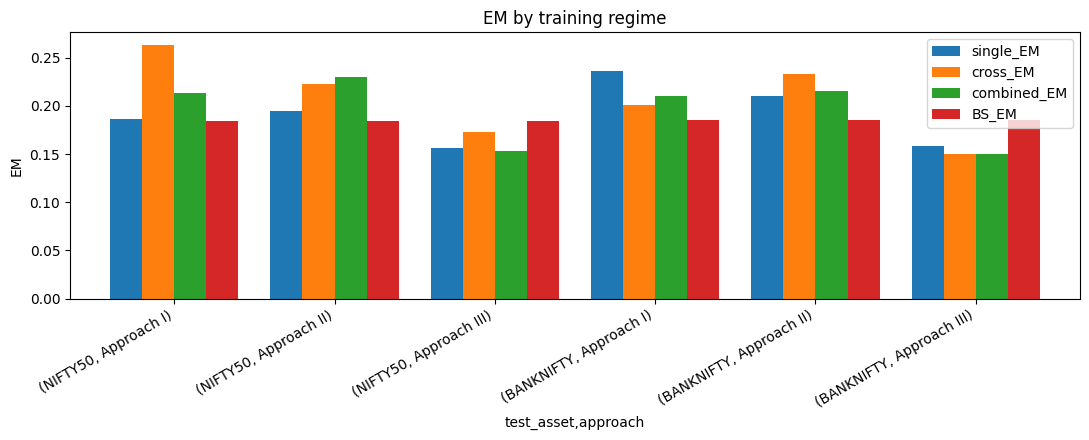


Best regime per (asset, approach):
test_asset  approach    
NIFTY50     Approach I            BS_EM
            Approach II           BS_EM
            Approach III    combined_EM
BANKNIFTY   Approach I            BS_EM
            Approach II           BS_EM
            Approach III       cross_EM
Name: lowest_EM, dtype: object


In [22]:
summary_rows = []
for name in ASSETS:
    for ap in APPROACHES:
        s = single_results.loc[(name, ap)]
        row = {'test_asset': name, 'approach': ap,
               'single_EM': s['EM'], 'single_rho': s['rho']}
        if MULTI_ASSET:
            other = [a for a in ASSETS if a != name][0]
            c = cross_results.loc[(other, name, ap)]
            row.update(cross_EM=c['EM'], cross_rho=c['rho'],
                       combined_EM=combined_results.loc[(ap, name), 'EM'],
                       combined_rho=combined_results.loc[(ap, name), 'rho'])
        row.update(BS_EM=BS[name]['EM'], BS_rho=BS[name]['rho'])
        summary_rows.append(row)

summary = pd.DataFrame(summary_rows).set_index(['test_asset', 'approach']).round(4)
print("=== EM / rho by training regime (lower is better) ===")
print(summary)

em_cols = [c for c in summary.columns if c.endswith('_EM')]
ax = summary[em_cols].plot(kind='bar', figsize=(11, 4.5), width=0.8)
ax.set_ylabel('EM'); ax.set_title('EM by training regime')
ax.axhline(0, color='black', lw=0.6)
plt.xticks(rotation=30, ha='right'); plt.tight_layout(); plt.show()

if MULTI_ASSET:
    print("\nBest regime per (asset, approach):")
    print(summary[em_cols].idxmin(axis=1).rename('lowest_EM'))

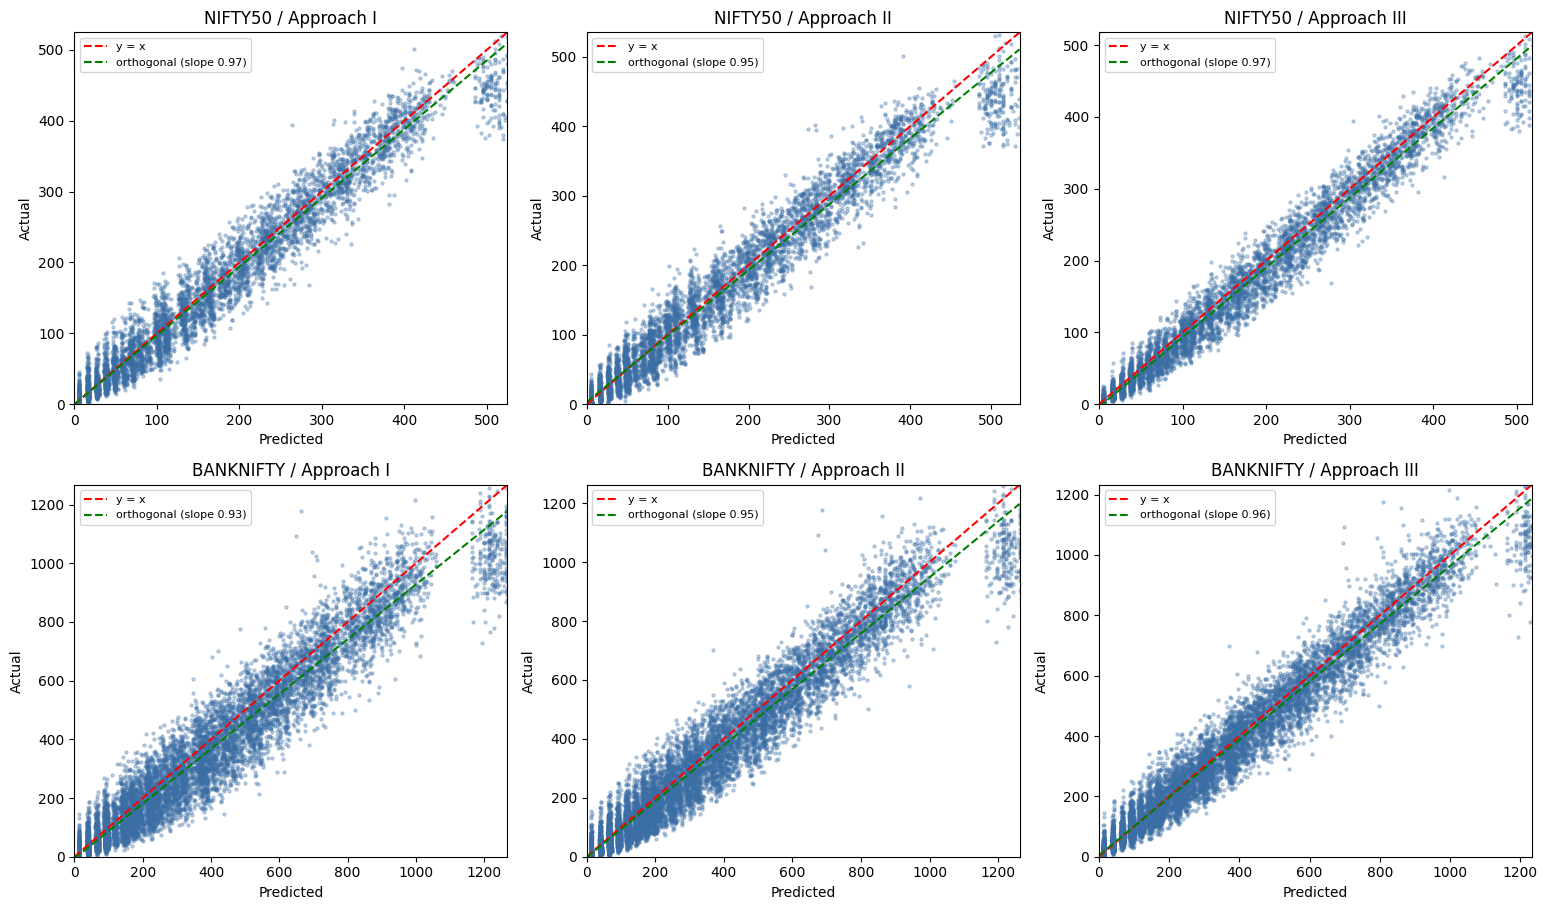

=== Band coverage and bias ===
                        P(|err|<=2)  P(|err|<=5)  q02  q98  tls_slope  mean_signed_error
asset     approach                                                                      
NIFTY50   Approach I         0.7215       0.9600 -6.0  5.0     0.9706             5.0547
          Approach II        0.7243       0.9459 -8.0  5.0     0.9483             5.4784
          Approach III       0.7832       0.9726 -6.0  3.0     0.9712             8.8046
BANKNIFTY Approach I         0.6335       0.9036 -9.0  5.0     0.9338            30.4258
          Approach II        0.6760       0.9382 -8.0  5.0     0.9504            19.9427
          Approach III       0.7879       0.9653 -6.0  4.0     0.9595             9.6777

1 - rho is the confidence the true bin lies in [P-2, P+2];
mean_signed_error near zero means no systematic over/under-pricing.


In [23]:
def orthogonal_regression(x, y):
    x, y = np.asarray(x, float), np.asarray(y, float)
    m = np.isfinite(x) & np.isfinite(y)
    x, y = x[m], y[m]
    xm, ym = x.mean(), y.mean()
    _, _, vt = np.linalg.svd(np.column_stack([x-xm, y-ym]), full_matrices=False)
    vx, vy = vt[0]
    slope = vy/vx
    return slope, ym - slope*xm


def bin_to_price(bins, strike):
    return (np.asarray(bins, float) - 0.5) * W_BIN * np.asarray(strike, float) / 100.0


diag_rows = []
fig, axes = plt.subplots(len(ASSETS), len(APPROACHES), figsize=(5.2*len(APPROACHES), 4.6*len(ASSETS)),
                         squeeze=False)
for i, name in enumerate(ASSETS):
    d_test = DATA[name].loc[SPLIT[name]['test']].reset_index(drop=True)
    for j, ap in enumerate(APPROACHES):
        p = SINGLE_PRED[(name, ap)]
        err = p['y_true'].astype(float) - p['pred'].astype(float)
        pred_px = bin_to_price(p['pred'], d_test['strike'].values)
        act_px = d_test['close'].values
        slope, intercept = orthogonal_regression(pred_px, act_px)

        ax = axes[i][j]
        lim = np.nanpercentile(np.concatenate([pred_px, act_px]), 99.5)
        ax.scatter(pred_px, act_px, s=5, alpha=0.3, color='#3b6ea5')
        xs = np.linspace(0, lim, 50)
        ax.plot(xs, xs, 'r--', label='y = x')
        ax.plot(xs, slope*xs + intercept, 'g--', label=f'orthogonal (slope {slope:.2f})')
        ax.set_xlim(0, lim); ax.set_ylim(0, lim)
        ax.set_title(f'{name} / {ap}'); ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
        ax.legend(fontsize=8)

        diag_rows.append({'asset': name, 'approach': ap,
                          'P(|err|<=2)': np.mean(np.abs(err) <= 2),
                          'P(|err|<=5)': np.mean(np.abs(err) <= 5),
                          'q02': np.percentile(err, 2), 'q98': np.percentile(err, 98),
                          'tls_slope': slope, 'mean_signed_error': np.mean(pred_px - act_px)})
plt.tight_layout(); plt.show()

diagnostics = pd.DataFrame(diag_rows).set_index(['asset', 'approach']).round(4)
print("=== Band coverage and bias ===")
print(diagnostics)
print("\n1 - rho is the confidence the true bin lies in [P-2, P+2];")
print("mean_signed_error near zero means no systematic over/under-pricing.")

In [25]:
def assign_bins(d):
    d['output_ratio'] = 100 * d['close'] / d['strike']
    raw = np.ceil(d['output_ratio'] / W_BIN).astype(int).clip(lower=1)
    d['bin_label'] = np.where(raw > CUTOFF_BIN, NUM_CLASSES, raw)
    return d

COVID_DATA, COVID_FEATS = {}, {}
if RUN_COVID:
    for name, files in COVID_FILES.items():
        d, _ = build_asset_dataset(name, files, bonds, date_min=COVID_START, date_max=COVID_END)
        d = assign_bins(d)
        d['hist_vol'] = log_returns_from_lookback(d, 'close').std(axis=1, ddof=1) * np.sqrt(252)
        COVID_DATA[name] = d
        COVID_FEATS[name] = {ap: APPROACH_BUILDERS[ap](d) for ap in COVID_APPROACHES}
        for ap in COVID_APPROACHES:      # must match the training matrices column for column
            assert list(COVID_FEATS[name][ap].columns) == list(FEATURES[name][ap].columns), (name, ap)
        print(f"[{name}] overflow-bin share in COVID window: {100*(d['bin_label']==NUM_CLASSES).mean():.2f}% "
              f"(training data: {100*(DATA[name]['bin_label']==NUM_CLASSES).mean():.2f}%)")
else:
    print("RUN_COVID = False -> skipped")

[NIFTY50] raw=685,439  filtered=11,580  (2019-01-02 to 2020-04-30)
[NIFTY50] overflow-bin share in COVID window: 3.68% (training data: 2.41%)
[BANKNIFTY] raw=292,082  filtered=12,541  (2019-01-01 to 2020-04-30)
[BANKNIFTY] overflow-bin share in COVID window: 3.70% (training data: 2.55%)


[NIFTY50] annualised realised vol  train 0.143 | Oct-Dec 2019 0.101 | Jan-Mar 2020 0.486
[BANKNIFTY] annualised realised vol  train 0.194 | Oct-Dec 2019 0.164 | Jan-Mar 2020 0.574


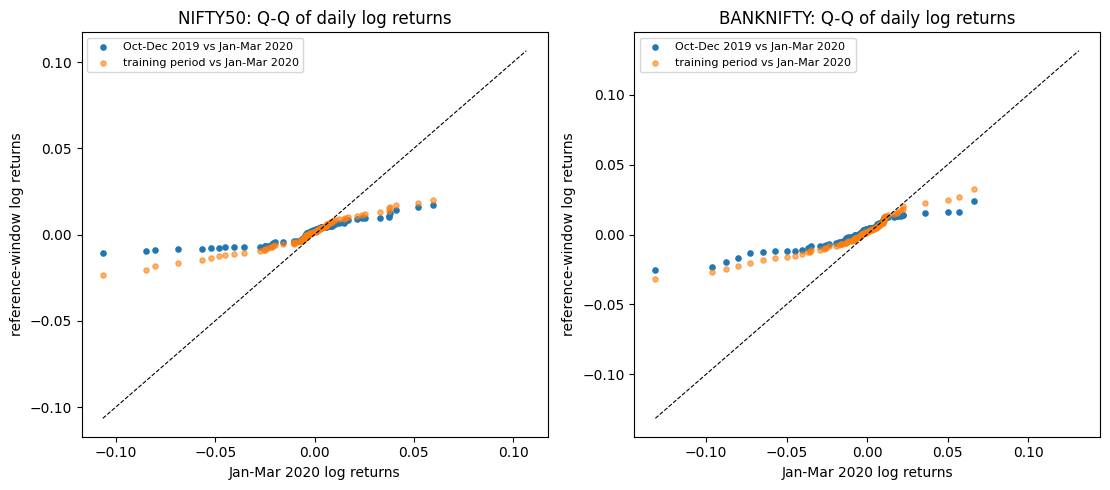

In [26]:
def window_returns(spot_path, start, end):
    sp = load_spot(spot_path).set_index('date')['spot_close']
    lr = np.log(sp).diff().dropna()
    return lr[(lr.index >= start) & (lr.index <= end)]

if RUN_COVID:
    fig, axes = plt.subplots(1, len(COVID_FILES), figsize=(5.6*len(COVID_FILES), 5), squeeze=False)
    qs = np.linspace(0.01, 0.99, 99)
    for ax, (name, files) in zip(axes[0], COVID_FILES.items()):
        pre   = window_returns(files['spot'], '2019-10-01', '2019-12-31')
        crash = window_returns(files['spot'], '2020-01-01', '2020-03-31')
        train = window_returns(files['spot'], DATA_START or '2015-01-01', TRAIN_END)
        ax.scatter(np.quantile(crash, qs), np.quantile(pre, qs), s=14, label='Oct-Dec 2019 vs Jan-Mar 2020')
        ax.scatter(np.quantile(crash, qs), np.quantile(train, qs), s=14, alpha=0.6, label='training period vs Jan-Mar 2020')
        lim = max(abs(np.quantile(crash, [0.01, 0.99])).max(), 0.05)
        ax.plot([-lim, lim], [-lim, lim], 'k--', lw=0.8)
        ax.set_xlabel('Jan-Mar 2020 log returns'); ax.set_ylabel('reference-window log returns')
        ax.set_title(f'{name}: Q-Q of daily log returns'); ax.legend(fontsize=8)
        ann = lambda r: r.std(ddof=1) * np.sqrt(252)
        print(f"[{name}] annualised realised vol  train {ann(train):.3f} | Oct-Dec 2019 {ann(pre):.3f} | Jan-Mar 2020 {ann(crash):.3f}")
    plt.tight_layout(); plt.show()

In [27]:
def covid_models(name, ap):
    """Pre-trained bundles to test: the asset's own single model and the combined model."""
    out = {f'{name} (single)': SINGLE_BUNDLES[(name, ap)]}
    if MULTI_ASSET and ap in COMBINED_BUNDLES:
        out['Combined'] = COMBINED_BUNDLES[ap]
    return out

def period_masks(d):
    crash = (d['date'] >= pd.Timestamp(CRASH_START)).values
    return {'Full window': np.ones(len(d), bool), 'Pre-crash': ~crash, 'Crash': crash}

COVID_PRED, covid_rows = {}, []
if RUN_COVID:
    for name, d in COVID_DATA.items():
        bs_price = black_scholes_call(d['underlying'], d['strike'], d['time_to_maturity_yrs'],
                                      d['risk_free_rate'] / 100, d['hist_vol'])
        bs_bin = price_to_bin(bs_price, d['strike'])
        for ap in COVID_APPROACHES:
            X, y, cols = split_xy(COVID_FEATS[name][ap], np.ones(len(d), bool))
            for label, b in covid_models(name, ap).items():
                assert b['columns'] == cols, f"feature mismatch for {label}"
                pred, _ = score(b, X, y)
                COVID_PRED[(name, ap, label)] = pred
                for pname, pm in period_masks(d).items():
                    if pm.sum() == 0:
                        continue
                    covid_rows.append({'asset': name, 'approach': ap, 'model': label, 'period': pname,
                                       'n': int(pm.sum()), 'EM': em_metric(y[pm], pred[pm]),
                                       'rho': rho_metric(y[pm], pred[pm]), 'A': acc_metric(y[pm], pred[pm])})
            for pname, pm in period_masks(d).items():
                if pm.sum() == 0:
                    continue
                covid_rows.append({'asset': name, 'approach': ap, 'model': 'Black-Scholes', 'period': pname,
                                   'n': int(pm.sum()), 'EM': em_metric(y[pm], bs_bin[pm]),
                                   'rho': rho_metric(y[pm], bs_bin[pm]), 'A': acc_metric(y[pm], bs_bin[pm])})

    covid_results = (pd.DataFrame(covid_rows)
                     .set_index(['asset', 'approach', 'period', 'model']).sort_index().round(4))
    print("=== Table 11: models trained on 2015-2017, tested on the COVID window ===")
    print(covid_results)

    print("\nReference - same models on the 2017-18 test set (Experiment 1 / 4):")
    for name in COVID_DATA:
        for ap in COVID_APPROACHES:
            s_ = single_results.loc[(name, ap)]
            line = f"  {name} {ap}: single EM {s_['EM']:.4f} rho {s_['rho']:.4f}"
            if MULTI_ASSET and (ap, name) in combined_results.index:
                c_ = combined_results.loc[(ap, name)]
                line += f" | combined EM {c_['EM']:.4f} rho {c_['rho']:.4f}"
            print(line + f" | B-S EM {BS[name]['EM']:.4f} rho {BS[name]['rho']:.4f}")


=== Table 11: models trained on 2015-2017, tested on the COVID window ===
                                                           n      EM     rho       A
asset     approach     period      model                                            
BANKNIFTY Approach III Crash       BANKNIFTY (single)    514  0.6134  0.5837  0.3833
                                   Black-Scholes         514  0.7035  0.6109  0.3482
                                   Combined              514  0.7568  0.5798  0.3911
                       Full window BANKNIFTY (single)  12541  0.3263  0.4822  0.1765
                                   Black-Scholes       12541  0.3313  0.3977  0.1970
                                   Combined            12541  0.3168  0.4449  0.1924
                       Pre-crash   BANKNIFTY (single)  12027  0.3140  0.4778  0.1676
                                   Black-Scholes       12027  0.3154  0.3885  0.1906
                                   Combined            12027  0.2980  0.4391

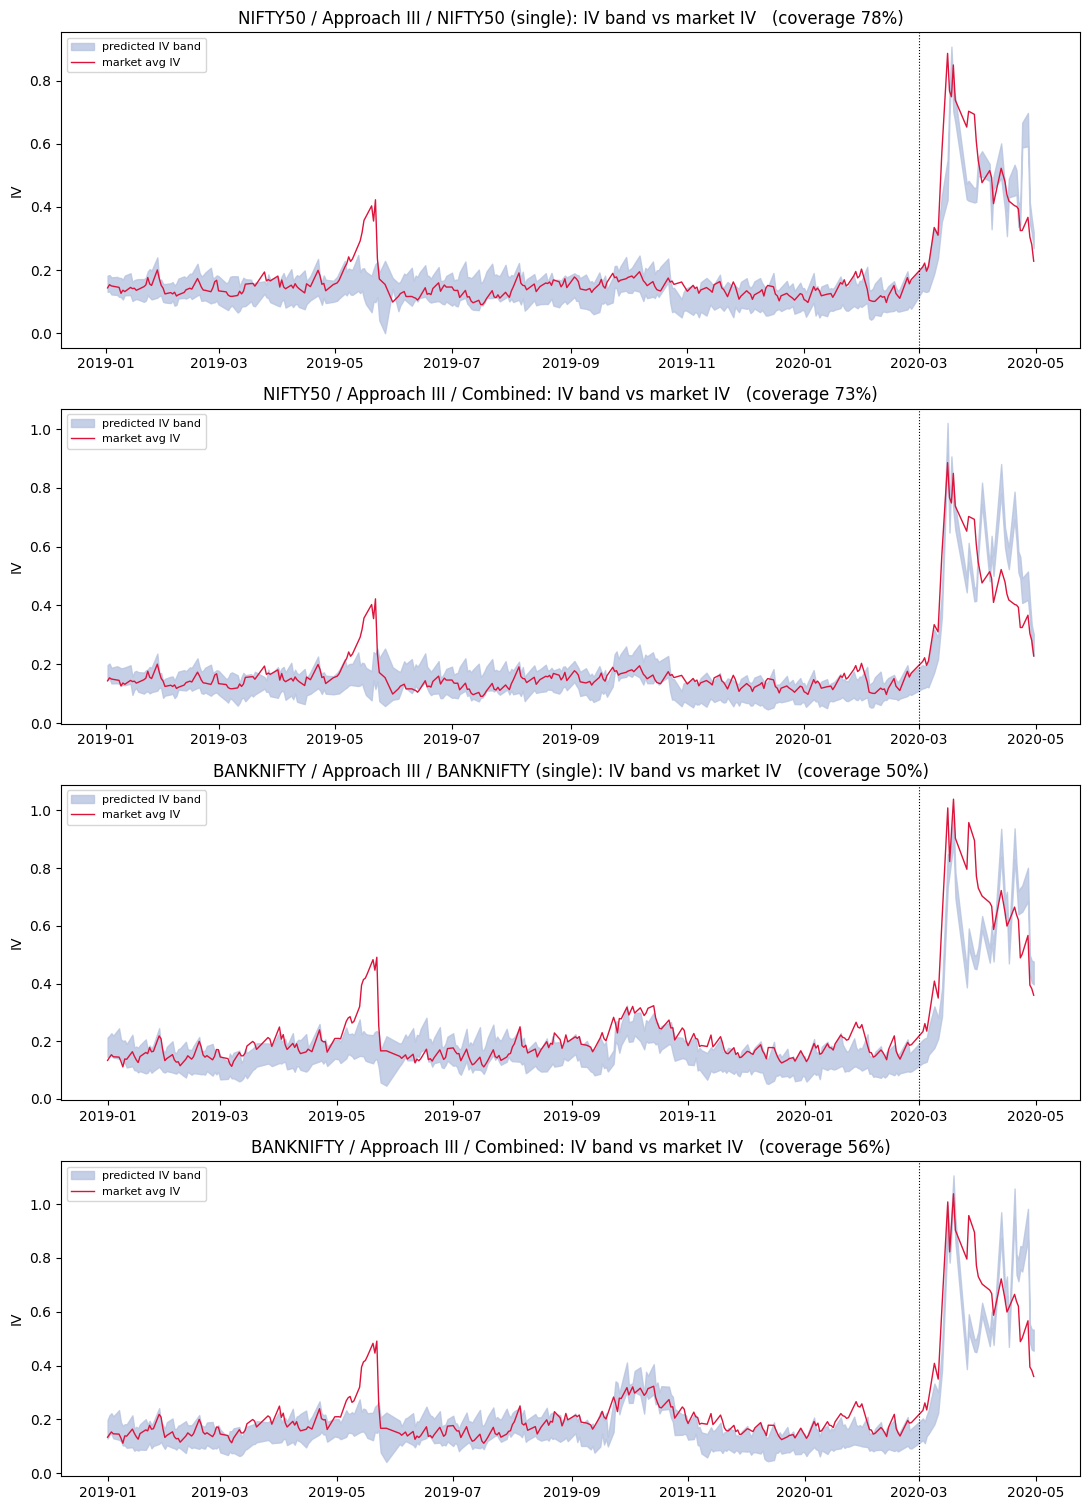

=== Share of days the market IV lies inside the predicted band (paper: ~90% in 2018, ~75% in COVID) ===
                                                           band_coverage
asset     approach     model              window                        
NIFTY50   Approach III NIFTY50 (single)   COVID (full)             0.785
                                          COVID pre-crash          0.848
                                          COVID crash              0.265
                                          2017-18 test             0.803
                       Combined           COVID (full)             0.727
                                          COVID pre-crash          0.798
                                          COVID crash              0.147
BANKNIFTY Approach III BANKNIFTY (single) COVID (full)             0.498
                                          COVID pre-crash          0.551
                                          COVID crash              0.061
                    

In [30]:
def implied_vol_call(price, S, K, T, r, lo=1e-4, hi=5.0, iters=60):
    """Vectorised bisection on the Black-Scholes call price. NaN where no IV exists."""
    price, S, K, T, r = [np.asarray(x, float) for x in (price, S, K, T, r)]
    intrinsic = np.maximum(S - K * np.exp(-r * T), 0.0)
    valid = (price > intrinsic + 1e-8) & (price < S)
    a, b = np.full(price.shape, lo), np.full(price.shape, hi)
    for _ in range(iters):
        m = 0.5 * (a + b)
        too_high = black_scholes_call(S, K, T, r, m) > price
        b = np.where(too_high, m, b)
        a = np.where(too_high, a, m)
    iv = 0.5 * (a + b)
    iv[~valid | (iv > hi - 1e-3)] = np.nan
    return iv


def iv_band_frame(d, pred_bins):
    """Daily market IV (from the actual close) and the IV of the lower / upper edge of the
    predicted band [P-2, P+2], averaged per day over the near-ATM contracts (paper Sec. 5.2)."""
    K = d['strike'].values
    S = d['underlying'].values
    T = d['time_to_maturity_yrs'].values
    r = d['risk_free_rate'].values / 100
    lo_px = np.clip((pred_bins - 3), 0, None) * W_BIN * K / 100.0      # lower edge of bin P-2
    hi_px = (pred_bins + 2) * W_BIN * K / 100.0                         # upper edge of bin P+2
    f = pd.DataFrame({'date': d['date'].values,
                      'iv_mkt': implied_vol_call(d['close'].values, S, K, T, r),
                      'iv_lo':  implied_vol_call(lo_px, S, K, T, r),
                      'iv_hi':  implied_vol_call(hi_px, S, K, T, r)})
    return f.groupby('date').mean().dropna(subset=['iv_mkt', 'iv_hi'])   # lower edge may be NaN near 0 price


def band_coverage(f):
    lo = f['iv_lo'].fillna(0.0)
    return float(((f['iv_mkt'] >= lo) & (f['iv_mkt'] <= f['iv_hi'])).mean())


if RUN_COVID:
    cov_rows = []
    keys = list(COVID_PRED)
    fig, axes = plt.subplots(len(keys), 1, figsize=(11, 3.8*len(keys)), squeeze=False)
    for ax, (name, ap, label) in zip(axes[:, 0], keys):
        d = COVID_DATA[name]
        f = iv_band_frame(d, COVID_PRED[(name, ap, label)])
        ax.fill_between(f.index, f['iv_lo'].fillna(0), f['iv_hi'], color='#b7c4e0', alpha=0.8, label='predicted IV band')
        ax.plot(f.index, f['iv_mkt'], color='crimson', lw=1, label='market avg IV')
        ax.axvline(pd.Timestamp(CRASH_START), color='k', ls=':', lw=0.8)
        cov_all = band_coverage(f)
        crash_f = f[f.index >= pd.Timestamp(CRASH_START)]
        pre_f   = f[f.index <  pd.Timestamp(CRASH_START)]
        cov_rows.append({'asset': name, 'approach': ap, 'model': label, 'window': 'COVID (full)', 'band_coverage': cov_all})
        if len(pre_f):   cov_rows.append({'asset': name, 'approach': ap, 'model': label, 'window': 'COVID pre-crash', 'band_coverage': band_coverage(pre_f)})
        if len(crash_f): cov_rows.append({'asset': name, 'approach': ap, 'model': label, 'window': 'COVID crash', 'band_coverage': band_coverage(crash_f)})

        # reference: same model on the 2017-18 test set (paper reports ~90%)
        if label == f'{name} (single)' and (name, ap) in SINGLE_PRED:
            d_te = DATA[name].loc[SPLIT[name]['test']].reset_index(drop=True)
            cov_rows.append({'asset': name, 'approach': ap, 'model': label, 'window': '2017-18 test',
                             'band_coverage': band_coverage(iv_band_frame(d_te, SINGLE_PRED[(name, ap)]['pred']))})
        ax.set_title(f'{name} / {ap} / {label}: IV band vs market IV   (coverage {cov_all:.0%})')
        ax.set_ylabel('IV'); ax.legend(loc='upper left', fontsize=8)
    plt.tight_layout(); plt.show()

    band_table = pd.DataFrame(cov_rows).set_index(['asset', 'approach', 'model', 'window']).round(3)
    print("=== Share of days the market IV lies inside the predicted band (paper: ~90% in 2018, ~75% in COVID) ===")
    print(band_table)
    print("\nThe model misses where IV jumps sharply - sentiment shifts that the 2015-2017 training data never contained.")

In [32]:
print("=" * 80)
print("SINGLE-ASSET (Tables 4/5)"); print(single_results[['EM', 'rho', 'A']])
print("\nBLACK-SCHOLES BENCHMARK"); print(bs_table)
if MULTI_ASSET:
    print("\nCROSS-ASSET (Table 8)"); print(cross_results[['EM', 'rho']])
    print("\nCOMBINED / MULTI-ASSET (Table 9)"); print(combined_results[['EM', 'rho']])
print("\nALL REGIMES"); print(summary)
print("\nBAND COVERAGE / BIAS"); print(diagnostics[['P(|err|<=2)', 'mean_signed_error']])
if RUN_COVID and 'covid_results' in globals():
    print("\nCOVID WINDOW (Table 11)"); print(covid_results[['n', 'EM', 'rho']])
    print("\nIV BAND COVERAGE"); print(band_table)
print("=" * 80)

with pd.ExcelWriter('kan_results_old.xlsx') as xl:
    single_results.to_excel(xl, sheet_name='single_asset')
    bs_table.to_excel(xl, sheet_name='black_scholes')
    if MULTI_ASSET:
        cross_results.to_excel(xl, sheet_name='cross_asset')
        combined_results.to_excel(xl, sheet_name='combined')
    summary.to_excel(xl, sheet_name='all_regimes')
    if RUN_COVID:
        covid_results.to_excel(xl, sheet_name='covid_table11')
        band_table.to_excel(xl, sheet_name='covid_iv_band')
    diagnostics.to_excel(xl, sheet_name='diagnostics')
print("results written to result/kan_results_old.xlsx")

SINGLE-ASSET (Tables 4/5)
                            EM     rho       A
asset     approach                            
NIFTY50   Approach I    0.1862  0.2785  0.2251
          Approach II   0.1950  0.2757  0.2209
          Approach III  0.1568  0.2168  0.2705
BANKNIFTY Approach I    0.2365  0.3665  0.2064
          Approach II   0.2099  0.3240  0.2122
          Approach III  0.1588  0.2121  0.2945

BLACK-SCHOLES BENCHMARK
               EM     rho       A
NIFTY50    0.1845  0.2704  0.2464
BANKNIFTY  0.1851  0.2776  0.2419

CROSS-ASSET (Table 8)
                                       EM     rho
trained_on tested_on approach                    
NIFTY50    BANKNIFTY Approach I    0.2013  0.2944
                     Approach II   0.2329  0.3599
                     Approach III  0.1499  0.1983
BANKNIFTY  NIFTY50   Approach I    0.2632  0.4244
                     Approach II   0.2232  0.3689
                     Approach III  0.1734  0.2390

COMBINED / MULTI-ASSET (Table 9)
              